In [1]:
import numpy as np
import pandas as pd
import scipy.sparse as sparse
import itertools
import matplotlib
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from datetime import date
import re
# from tqdm import tqdm
import time
# from pybedtools import BedTool
import random
import math
import pickle
import seaborn as sns
from scipy.stats import percentileofscore, pearsonr, rankdata, describe, mode, fisher_exact
import scipy as sp
import scipy.stats as stats
# from scipy.spatial.distance import jaccard, euclidean, cosine
# import functools
# import operator
import gzip
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import pairwise_distances
import sys
import os
from functools import partial
from contextlib import closing
from multiprocessing import Pool
import re
import h5py
import tabix
import upsetplot
from wordcloud import WordCloud
from sklearn.decomposition import NMF, non_negative_factorization
from collections import Counter
from scipy.stats import hypergeom
from scipy.stats.mstats import gmean
from scipy.cluster import hierarchy

today = date.today()

In [2]:
def kde_wrapper(data, bw=0.1):
    fig = plt.figure()
    fig.patch.set_facecolor('white')
    
    sns.kdeplot(data, bw_adjust=bw)
    print(describe(data))
    print(mode(data))
    return fig

In [18]:
#load the data
DHS_hdf5 = '/home/ctrader/region_similarity/data/rank_based/regions_25kb_CT20230119.DHSsignal.z.rank.sigmoid.conv_sqrt_sigmoid_sim.max_priors.hdf5'
DHS_z_hdf5 = h5py.File(DHS_hdf5, 'r')
DHS_top_sim = DHS_z_hdf5['top_similarity_vals_sqrt_sigmoid'][:]
DHS_top_regions = DHS_z_hdf5['top_regions'][:]
DHS_priors = DHS_z_hdf5['priors'][:]
DHS_z_hdf5.close()

TF_hdf5 = '/home/ctrader/region_similarity/data/rank_based/regions_25kb_CT20230119.TFsignal.z.rank.sigmoid.conv_sqrt_sigmoid_sim.max_priors.hdf5'
TF_z_hdf5 = h5py.File(TF_hdf5, 'r')
TF_top_sim = TF_z_hdf5['top_similarity_vals_sqrt_sigmoid'][:]
TF_top_regions = TF_z_hdf5['top_regions'][:]
TF_priors = TF_z_hdf5['priors'][:]
TF_z_hdf5.close()

epi_hdf5 = '/home/ctrader/region_similarity/data/rank_based/regions_25kb_CT20230119.epilogos.maxstateperbin.officialstateorder.rank.sigmoid.conv_sqrt_sigmoid_sim.max_priors.hdf5'
epi_z_hdf5 = h5py.File(epi_hdf5, 'r')
epi_top_sim = epi_z_hdf5['top_similarity_vals_sqrt_sigmoid'][:]
epi_top_regions = epi_z_hdf5['top_regions'][:]
epi_priors = epi_z_hdf5['priors'][:]
epi_z_hdf5.close()

In [108]:
filename = '/home/ctrader/region_similarity/data/rank_based/epilogos.winningstateperbin.genomewide.counts.expectedratio.officialorder.CT20230118.tsv'
expected = []
f = open(filename, 'r')
for line in f.readlines():
    expected.append(line.strip().split('\t'))
expected = np.array(expected)
f.close()

In [100]:
np.sum(expected[1].astype(int))

14102151

In [107]:
239335 + 159946

399281

In [106]:
(239335 + 159946) / 14102151

0.02831348210638221

In [104]:
expected[:, [8, 9]]

array([['EnhA1', 'EnhA2'],
       ['239335', '159946'],
       ['0.016971524414963364', '0.011341957691418847']], dtype='<U21')

In [19]:
filename = '/home/ctrader/region_similarity/data/rank_based/hg38.25kb.maxMean.CT20230118.sorted.bed'
f = open(filename, 'r')
regions = []
for line in f.readlines():
    r = line.strip().split('\t')
    regions.append(r)
f.close()
regions = np.array(regions)

In [20]:
hdf5_file = h5py.File(DHS_hdf5, 'r')
DHS_ranks = hdf5_file['ranked_data'][:]
hdf5_file.close()

hdf5_file = h5py.File(epi_hdf5, 'r')
epi_ranks = hdf5_file['ranked_data'][:]
hdf5_file.close()

In [21]:
hdf5_file = h5py.File(DHS_hdf5, 'r')
DHS_sigmoid = hdf5_file['sigmoid_data'][:]
hdf5_file.close()

hdf5_file = h5py.File(epi_hdf5, 'r')
epi_sigmoid = hdf5_file['sigmoid_data'][:]
hdf5_file.close()

**All at once**

In [22]:
def load_rank_path(hdf5_path, roi):
    hdf5_file = h5py.File(hdf5_path, 'r')
    rank_arr = hdf5_file['ranked_data'][roi]
    max_ranks = hdf5_file['max_ranks'][:]
    hdf5_file.close()
    return rank_arr, max_ranks


def get_factor_order(path):
    if path[-5:] == '.hdf5':
        hdf5_file = h5py.File(path, 'r')
        factor_order = np.char.decode(hdf5_file['comp_order'][:])
        hdf5_file.close()
    else:
        f = open(path, 'r')
        factor_order = np.array(f.readline().strip().split('\t'))[3:]
        f.close()
    return factor_order


def regional_sentence(rank_arrs, factor_arrs, max_rank_arrs, metric_name_arrs,
                      conversion_dicts, max_rank=20, multiple_rank_thresh=5,
                      max_factors_per_metric=3):

    num_metrics = len(rank_arrs)
    num_regions = len(rank_arrs[0])

    # establish sentences
    sentences = np.array([''] * num_regions, dtype=object)
    sentence_start = 'This region ranks in the top '
    sentences[:] = sentence_start

    sentence_section_arr = []
    sentence_section_best_ranks = []

    backup_rank = -np.ones(num_regions)
    backup_factor = np.array([''] * num_regions, dtype=object)
    backup_metric = np.array([''] * num_regions, dtype=object)

    # ranks for each metric
    for (rank_arr, factor_arr,
         max_ranks, metric_name,
         conversion_dict, metric_i) in zip(rank_arrs, factor_arrs,
                                           max_rank_arrs,
                                           metric_name_arrs,
                                           conversion_dicts,
                                           range(num_metrics)):

        # find percent of rank compared to max rank of each factor
        adjusted_ranks = rank_arr / (max_ranks + 1)  # pseudocount
        # find the top ranking factor
        rank_sort_order = np.argsort(-adjusted_ranks, axis=1)
        ranks_sorted = -np.sort(-adjusted_ranks, axis=1)

        # int of rank percentage
        # ranks_percent = np.ceil((1 - ranks_sorted) * 100).astype(int)
        ranks_percent = (1 - ranks_sorted) * 100
        ranks_percent = np.where(ranks_percent < 1,
                                 np.ceil(ranks_percent * 100) / 100,
                                 np.ceil(ranks_percent))
        # set top 0% ranks to top 1% ranks

        # the ranks to include
        # include all values that rank in the top multiple_rank_thresh percent
        ranks_mask = ranks_percent <= multiple_rank_thresh
        # include top factor if rank is in the top max_rank percent
        ranks_mask[:, 0] = ((ranks_mask[:, 0]) |
                            (ranks_percent[:, 0] <= max_rank))
        # number of factors to include for each region
        num_factors_per_region = np.count_nonzero(ranks_mask, axis=1)

        # find name of top factor
        factors_ranked = factor_arr[rank_sort_order]
        # convert to a readable version of name
        factors_ranked = np.array(list(map(
                                           conversion_dict.get,
                                           factors_ranked.flatten()
                                       ))).reshape(factors_ranked.shape)

        # metric in sentence form
        metric_arr = np.char.add(' ', np.array([metric_name] * num_regions))

        # backup for regions
        better_backup_mask = ranks_sorted[:, 0] > backup_rank
        backup_rank[better_backup_mask] = ranks_sorted[:, 0][
                                              better_backup_mask
                                          ]
        backup_factor[better_backup_mask] = factors_ranked[:, 0][
                                                better_backup_mask
                                            ]
        backup_metric[better_backup_mask] = metric_arr[better_backup_mask]

        # initializing the section of the sentence for current metric
        sentence_section = np.array([''] * num_regions)

        metric_ranks_per_region = []
        # for each factor in order of how they rank for each region,
        # add to sentence section
        for factor in range(len(factor_arr))[:max_factors_per_metric]:
            if (
                (len(ranks_mask[:, factor][ranks_mask[:, factor]]) == 0) &
                (factor != 0)
            ):
                break
            # mask for factor
            factor_mask = ~ranks_mask[:, factor]
            # percentage
            factor_rank_percent = ranks_percent[:, factor].astype(str)
            factor_rank_percent[factor_mask] = ''

            # saving the rank values for each region
            metric_ranks_per_region.append(np.where(factor_mask, np.nan,
                                                    ranks_sorted[:, factor]))

            # filler between percent and factor name
            per_of = np.array(['% of '] * num_regions)
            per_of[factor_mask] = ''
            # factor name
            factor_name = factors_ranked[:, factor]
            factor_name[factor_mask] = ''

            # ending
            factor_ending = np.array([''] * num_regions, dtype=object)
            # for regions with more factors than max_factors_per_metric
            # with ranks better than multiple_rank_thresh
            # if there is 1 factor left
            if (factor + 2) == max_factors_per_metric:
                if factor == 0:
                    factor_ending[
                        num_factors_per_region >= (factor + 2)
                    ] = ' and '  # >
                else:
                    factor_ending[
                        num_factors_per_region >= (factor + 2)
                    ] = ', and '  # >
            # if there are no factors left
            elif (factor + 1) == max_factors_per_metric:
                # >
                factor_ending[num_factors_per_region >= (factor + 2)] = ''
            else:  # many factors left
                factor_ending[num_factors_per_region > (factor + 2)] = ', '
                if factor == 0:
                    factor_ending[
                        num_factors_per_region == (factor + 2)
                    ] = ' and '
                else:
                    factor_ending[
                        num_factors_per_region == (factor + 2)
                    ] = ', and '

            # append factor info to sentence section
            sentence_section = np.char.add(sentence_section,
                                           factor_rank_percent)
            sentence_section = np.char.add(sentence_section, per_of)
            sentence_section = np.char.add(sentence_section, factor_name)
            sentence_section = np.char.add(sentence_section, factor_ending)

        # add the metric to the sentence section
        metric_arr[~ranks_mask[:, 0]] = ''
        sentence_section = np.char.add(sentence_section, metric_arr)

        sentence_section_arr.append(sentence_section)

        # best ranks for each region
        metric_ranks_per_region = np.array(metric_ranks_per_region).T
        sentence_section_best_ranks.append(np.nanmax(metric_ranks_per_region,
                                                     axis=1))

    sentence_section_arr = np.array(sentence_section_arr).T
    sentence_section_best_ranks = np.array(sentence_section_best_ranks).T
    sorted_sections = np.argsort(-sentence_section_best_ranks, axis=1)

    # to know where to place '.', ',' and 'and'
    num_sections_with_ranks = np.count_nonzero(
                                  ~np.isnan(sentence_section_best_ranks),
                                  axis=1
                              )

    # add sections to sentences
    for section in range(num_metrics):
        sentences = np.char.add(sentences.astype(str),
                                sentence_section_arr[
                                    np.arange(len(sorted_sections)),
                                    sorted_sections[:, section]
                                ])
        section_ending = np.array([', '] * num_regions, dtype=object)
        section_ending[num_sections_with_ranks == (section + 1)] = '.'
        section_ending[num_sections_with_ranks < (section + 1)] = ''
        section_ending[(num_sections_with_ranks == (section + 2)) &
                       (num_sections_with_ranks != 2)] = ', and '
        section_ending[(num_sections_with_ranks == (section + 2)) &
                       (num_sections_with_ranks == 2)] = ' and '
        sentences = np.char.add(sentences.astype(str),
                                section_ending)

    # fill with backup ranks for regions that don't match filters for any
    # metric
    need_backup_mask = sentences == sentence_start
    # rank
    backup_percent = np.ceil((1 - backup_rank) * 100).astype(int)
    sentences[need_backup_mask] = np.char.add(
                                      sentences[
                                          need_backup_mask
                                      ].astype(str),
                                      backup_percent[
                                          need_backup_mask
                                      ].astype(int).astype(str)
                                  )
    # fill between rank and factor
    sentences[need_backup_mask] = np.char.add(
                                      sentences[need_backup_mask].astype(str),
                                      np.array(['% of '] * num_regions)[
                                          need_backup_mask
                                      ]
                                  )
    # factor
    sentences[need_backup_mask] = np.char.add(
                                      sentences[need_backup_mask].astype(str),
                                      backup_factor[need_backup_mask]
                                  )
    # metric
    sentences[need_backup_mask] = np.char.add(
                                      sentences[need_backup_mask].astype(str),
                                      backup_metric[need_backup_mask]
                                  )
    # .
    sentences[need_backup_mask] = np.char.add(
                                      sentences[need_backup_mask].astype(str),
                                      np.array(['.'] * num_regions)[
                                          need_backup_mask
                                      ]
                                  )
    return sentences


def make_sentences(DHS_hdf5_path, DHS_mapped_path, TF_hdf5_path,
                   TF_mapped_path, epilogos_hdf5_path, #epilogos_mapped_path, 
                   roi):
    # load rank arrays
    DHS_rank_arr, DHS_max_ranks = load_rank_path(DHS_hdf5_path, roi) #
    TF_rank_arr, TF_max_ranks = load_rank_path(TF_hdf5_path, roi) #
    epi_rank_arr, epi_max_ranks = load_rank_path(epilogos_hdf5_path, roi) #

    # load factor orders
    DHS_factor_order = get_factor_order(DHS_mapped_path)
    TF_factor_order = get_factor_order(TF_mapped_path)
#     epi_factor_order = get_factor_order(epilogos_mapped_path)
    epi_factor_order = np.array(['TssA', 'TssFlnk', 'TssFlnkU', 
                                 'TssFlnkD', 'Tx', 'TxWk', 'EnhG1', 
                                 'EnhG2', 'EnhA1', 'EnhA2', 'EnhWk', 
                                 'ZNF_Rpts', 'Het', 'TssBiv', 'EnhBiv', 
                                 'ReprPC', 'ReprPCWk', 'Quies'])

    # conversion dictionaries
    epi_conversion_dict = {
        'EnhA1': 'active enhancer 1',
        'EnhA2': 'active enhancer 2',
        'EnhBiv': 'bivalent enhancer',
        'EnhG1': 'genic enhancer 1',
        'EnhG2': 'genic enhancer 2',
        'EnhWk': 'weak enhancer',
        'Het': 'heterochromatin',
        'Quies': 'quiescent',
        'ReprPC': 'repressed polycomb',
        'ReprPCWk': 'weak repressed polycomb',
        'TssA': 'active TSS',
        'TssBiv': 'bivalent TSS',
        'TssFlnk': 'flanking TSS',
        'TssFlnkD': 'downstream flanking TSS',
        'TssFlnkU': 'upstream flanking TSS',
        'Tx': 'strong transcription',
        'TxWk': 'weak transcription',
        'ZNF_Rpts': 'ZNF genes + repeats'
    }

    DHS_conversion_dict = {
        'Cancer_epithelial': 'cancer/epithelial',
        'Cardiac': 'cardiac',
        'Digestive': 'digestive',
        'Lymphoid': 'lymphoid',
        'Musculoskeletal': 'musculoskeletal',
        'Myeloid_erythroid': 'myeloid/erythroid',
        'Neural': 'neural',
        'Organdevel_renal': 'organ development/renal',
        'Placental_trophoblast': 'placental/trophoblast',
        'Primitive_embryonic': 'primitive/embryonic',
        'Pulmonarydevel': 'pulmonary development',
        'Renal_cancer': 'renal/cancer',
        'StromalA': 'stromal A',
        'StromalB': 'stromal B',
        'Tissueinvariant': 'tissue invariant',
        'Vascular_endothelial': 'vascular/endothelial'
    }

    TF_conversion_dict = {}
    for factor in TF_factor_order:
        TF_conversion_dict[factor] = factor

    rank_arrs = [DHS_rank_arr, TF_rank_arr, epi_rank_arr]
    factor_arrs = [DHS_factor_order, TF_factor_order, epi_factor_order]
    max_rank_arrs = [DHS_max_ranks, TF_max_ranks, epi_max_ranks]
    metric_name_arrs = ['DHS signal', 'TF motif scores', 
                        'chromatin states']
    conversion_dicts = [DHS_conversion_dict, TF_conversion_dict,
                        epi_conversion_dict]

    sentences = regional_sentence(rank_arrs, factor_arrs, max_rank_arrs,
                                  metric_name_arrs, conversion_dicts,
                                  max_rank=10, multiple_rank_thresh=3,
                                  max_factors_per_metric=3)

    return sentences

In [5]:
datadir = '/home/ctrader/region_similarity/data/rank_based/'
DHS_hdf5_path = datadir + 'regions_25kb_CT20230119.DHSsignal.z.rank.sigmoid.conv_sqrt_sigmoid_sim.max_priors.hdf5'
DHS_mapped_path = datadir + 'regions_25kb_CT20230118.DHSsignalmapped.bed'
TF_hdf5_path = datadir + 'regions_25kb_CT20230119.TFsignal.z.rank.sigmoid.conv_sqrt_sigmoid_sim.max_priors.hdf5'
TF_mapped_path = datadir + 'regions_25kb_CT20230118.TFsignalmapped.bed'
epi_hdf5_path = datadir + 'regions_25kb_CT20230119.epilogos.maxstateperbin.officialstateorder.rank.sigmoid.conv_sqrt_sigmoid_sim.max_priors.hdf5'
roi = [66035]
make_sentences(DHS_hdf5_path, DHS_mapped_path, TF_hdf5_path,
               TF_mapped_path, epi_hdf5_path, #epilogos_mapped_path,
               roi)

array(['This region ranks in the top 0.01% of active TSS and 2.0% of upstream flanking TSS chromatin states, 0.32% of digestive, 0.48% of placental/trophoblast, and 0.99% of lymphoid DHS signal, and 3.0% of HD_17 and 3.0% of DMRT1 TF motif scores.'],
      dtype='<U701')

In [23]:
def get_top_regions(i):
    num_regions = len(DHS_top_sim)

    icoord = regions[i]
    icoord_print = icoord[0] + ':' + icoord[1] + '-' + icoord[2]
    print(icoord_print)

    DHS_arr = np.zeros(num_regions)
    TF_arr = np.zeros(num_regions)
    epi_arr = np.zeros(num_regions)

    #setting similarity values for each region
    DHS_arr[DHS_top_regions[i]] = DHS_top_sim[i]
    TF_arr[TF_top_regions[i]] = TF_top_sim[i]
    epi_arr[epi_top_regions[i]] = epi_top_sim[i]

    #fusion score with priors
    fusion_i = 1 - ((1 - (DHS_priors[i] * DHS_arr)) * 
                    (1 - (TF_priors[i] * TF_arr)) * 
                    (1 - (epi_priors[i] * epi_arr)))

    #top 100
    top_100 = np.append([i], np.argsort(-fusion_i)[:100])
    print('DHS Priors', np.round(DHS_priors[i], 4))
    print('TF Priors', np.round(TF_priors[i], 4))
    print('Epilogos Priors', np.round(epi_priors[i], 4))
    return top_100, np.array([DHS_priors[i], TF_priors[i], epi_priors[i]])

top_100, priors = get_top_regions(0)

chr1:22400-47400
DHS Priors 0.0067
TF Priors 0.1056
Epilogos Priors 0.0478


In [392]:
for simregion in top_100:
    print(make_sentences(DHS_hdf5_path, DHS_mapped_path, TF_hdf5_path,
                         TF_mapped_path, epi_hdf5_path, #epilogos_mapped_path,
                         [simregion]))

['This region ranks in the top 0.01% of active TSS and 2.0% of upstream flanking TSS chromatin states, 0.32% of digestive, 0.48% of placental/trophoblast, and 0.99% of lymphoid DHS signal, and 3.0% of HD_17 and 3.0% of DMRT1 TF motif scores.']
['This region ranks in the top 0.49% of primitive/embryonic, 2.0% of stromal B, and 3.0% of tissue invariant DHS signal, 2.0% of ARI5B and 2.0% of CREB_ATF_1 TF motif scores, and 4.0% of upstream flanking TSS chromatin states.']
['This region ranks in the top 0.12% of primitive/embryonic, 0.14% of myeloid/erythroid, and 0.53% of stromal B DHS signal, 0.13% of CREB_ATF_1, 0.18% of MYB_5, and 0.18% of CREB_ATF_2 TF motif scores, and 0.49% of upstream flanking TSS and 3.0% of active TSS chromatin states.']
['This region ranks in the top 0.07% of ZNF331, 0.09% of NFKB_2, and 0.11% of ZBTB7A TF motif scores, 0.24% of upstream flanking TSS chromatin states, and 0.37% of stromal B and 0.42% of primitive/embryonic DHS signal.']
['This region ranks in the

/tmp/ipykernel_5926/386732668.py:166: RuntimeWarning: All-NaN slice encountered
  sentence_section_best_ranks.append(np.nanmax(metric_ranks_per_region,


['This region ranks in the top 0.18% of NR_8, 0.19% of NR_12, and 0.38% of THAP1 TF motif scores, 2.0% of upstream flanking TSS and 3.0% of active TSS chromatin states, and 3.0% of primitive/embryonic DHS signal.']
['This region ranks in the top 0.23% of PRDM1 and 2.0% of NFAT_4 TF motif scores and 8.0% of weak enhancer chromatin states.']
['This region ranks in the top 2.0% of upstream flanking TSS chromatin states, 3.0% of TATA and 3.0% of HD_4 TF motif scores, and 3.0% of lymphoid DHS signal.']
['This region ranks in the top 0.75% of HINFP1_1, 2.0% of RUNX_2, and 2.0% of RUNX_1 TF motif scores, 0.84% of tissue invariant DHS signal, and 4.0% of active TSS chromatin states.']
['This region ranks in the top 0.33% of PAX-halfsite, 0.46% of ZNF143, and 0.5% of ZNF554 TF motif scores and 3.0% of stromal A and 3.0% of cardiac DHS signal.']
['This region ranks in the top 0.22% of ZNF435, 0.52% of BCL6_2, and 2.0% of ZNF680 TF motif scores, 3.0% of placental/trophoblast and 3.0% of primitive

['This region ranks in the top 0.07% of E2F_4, 0.13% of NR_5, and 0.13% of MBD2 TF motif scores, 2.0% of cardiac and 2.0% of tissue invariant DHS signal, and 3.0% of upstream flanking TSS chromatin states.']
['This region ranks in the top 0.24% of tissue invariant and 0.31% of lymphoid DHS signal and 0.37% of ZNF143, 0.57% of MAF, and 0.61% of Ebox_CACGTG_1 TF motif scores.']
['This region ranks in the top 0.62% of GATA and 2.0% of SPZ1 TF motif scores, 0.7% of cancer/epithelial and 3.0% of musculoskeletal DHS signal, and 2.0% of upstream flanking TSS chromatin states.']
['This region ranks in the top 3.0% of organ development/renal DHS signal, 5.0% of SPI TF motif scores, and 6.0% of upstream flanking TSS chromatin states.']
['This region ranks in the top 0.15% of stromal B, 0.32% of myeloid/erythroid, and 3.0% of tissue invariant DHS signal, 0.33% of NFKB_2 and 0.68% of MEF2 TF motif scores, and 2.0% of active enhancer 2 chromatin states.']
['This region ranks in the top 0.19% of SPD

['This region ranks in the top 0.13% of NR_8, 0.23% of CREB_ATF_2, and 0.29% of RBPJ TF motif scores, 0.91% of tissue invariant and 0.98% of digestive DHS signal, and 6.0% of active enhancer 1 chromatin states.']
['This region ranks in the top 0.04% of KLF_SP_1, 0.16% of E2F_2, and 0.21% of NR_3 TF motif scores, 0.08% of digestive and 2.0% of primitive/embryonic DHS signal, and 2.0% of upstream flanking TSS chromatin states.']
['This region ranks in the top 3.0% of NR_4, 3.0% of ZKSCAN1, and 3.0% of TCF_LEF TF motif scores, 3.0% of upstream flanking TSS chromatin states, and 4.0% of tissue invariant DHS signal.']
['This region ranks in the top 0.1% of AHR and 3.0% of SOX_5 TF motif scores, 0.62% of placental/trophoblast, 1.0% of tissue invariant, and 2.0% of organ development/renal DHS signal, and 3.0% of active enhancer 1 chromatin states.']
['This region ranks in the top 0.12% of NR_17, 0.24% of MYB_2, and 0.5% of ZNF335 TF motif scores, 0.64% of primitive/embryonic DHS signal, and 0

**Based on top factors of query region**

In [94]:
"""
This function sorts the regions of interest to load rank data from hdf5
file. The rank data is then resorted in the orginal order and returned
with the max ranks for each factor. 
"""
def load_ranks_top100(hdf5_path, roi):
    # sort order for hdf5 file
    sort_order = np.argsort(roi)

    hdf5_file = h5py.File(hdf5_path, 'r')
    rank_arr_sorted = hdf5_file['ranked_data'][roi[sort_order]]
    max_ranks = hdf5_file['max_ranks'][:]
    hdf5_file.close()
    
    # back to original order
    rank_arr = np.zeros(rank_arr_sorted.shape)
    rank_arr[sort_order] = rank_arr_sorted
    
    return rank_arr, max_ranks




class metriccolors:
    DHS = '\033[94m'
    TF = '\033[92m'
    EPI = '\033[91m'
    STANDARD = '\033[0m'
    BOLD = '\033[1m'
    UNDERLINE = '\033[4m'

def query_sentences(rank_arrs, factor_arrs_unordered, max_rank_arrs, 
                    metric_name_arrs_unordered, 
                    conversion_dicts_unordered, max_rank=20, 
                    multiple_rank_thresh=5,
                    max_factors_per_metric=3):
    num_metrics = len(rank_arrs)
    num_regions = len(rank_arrs[0])
#     num_metrics_skipped = 0

    # establish sentences
    sentences = np.array([''] * num_regions, dtype=object)
    sentence_start = f'This region ranks in the top '
    sentences[:] = sentence_start
    
    percent_arrs_unordered = []
    min_percents = []
    for rank_arr, max_rank_arr in zip(rank_arrs, max_rank_arrs):
        percent_arr, min_percent = percent_conversion(rank_arr, max_rank_arr)
        percent_arrs_unordered.append(percent_arr)
        min_percents.append(min_percent)
    min_percents = np.array(min_percents)

    # sorting by min percent
    percent_arr_order = np.argsort(min_percents)
    num_metrics_to_examine = len(min_percents[min_percents <= max_rank])
    percent_arrs = []
    factor_arrs = []
    metric_name_arrs = []
    conversion_dicts = []
    for p in percent_arr_order:
        percent_arrs.append(percent_arrs_unordered[p])
        factor_arrs.append(factor_arrs_unordered[p])
        metric_name_arrs.append(metric_name_arrs_unordered[p])
        conversion_dicts.append(conversion_dicts_unordered[p])
    
    top_percents = np.array([]).reshape(num_regions, -1)
    top_factors = np.array([])
    top_metrics = np.array([])
    # ranks for each metric
    for (
        percent_arr, factor_arr, metric_name,
        conversion_dict, metric_i
    ) in zip(
        percent_arrs[:num_metrics_to_examine], 
        factor_arrs[:num_metrics_to_examine], 
        metric_name_arrs[:num_metrics_to_examine], 
        conversion_dicts[:num_metrics_to_examine], 
        range(num_metrics_to_examine)
    ):
        # what is special about the query region?
        # sorting factors
        q_percent_sorted = np.sort(percent_arr[0])
        q_top_factors = np.argsort(percent_arr[0])

        # number of factors to examine for metric
        if len(q_percent_sorted[q_percent_sorted < multiple_rank_thresh]) > 0:
            num_factors = len(
                q_percent_sorted[
                    q_percent_sorted < multiple_rank_thresh
                ][:max_factors_per_metric]
            )
        elif len(q_percent_sorted[q_percent_sorted <= max_rank]) > 0:
            num_factors = 1
        else:
            print('BAD: this should not occur')
            num_factors = 0
#             num_metrics_skipped += 1
        # factor inds to examine
        factor_inds = q_top_factors[:num_factors]
        
        # factors and percentiles to save
        top_percents = np.hstack((top_percents, percent_arr[:, factor_inds]))
        top_factors = np.append(top_factors, factor_arr[factor_inds])
        top_metrics = np.append(top_metrics, np.array([metric_name] * len(factor_inds)))
        
        # coloring sentence sections
        if metric_name == 'DHS signal':
            metric_color = metriccolors.DHS
        elif metric_name == 'TF motif scores':
            metric_color = metriccolors.TF
        elif metric_name == 'chromatin states':
            metric_color = metriccolors.EPI
        sentences = np.char.add(sentences.astype(str), np.array([metric_color] * num_regions))
        
        # add factors to sentences
        for ind in factor_inds:
            factor_percent = percent_arr[:, ind]
            factor_percent = np.where((factor_percent % 1) != 0,
                                      factor_percent.astype(str),
                                      factor_percent.astype(int).astype(str))
            factor_percent = np.char.add(np.array([metriccolors.BOLD] * num_regions),
                                         factor_percent)
            factor_percent = np.char.add(factor_percent,
                                         np.array(['%' + metriccolors.STANDARD + 
                                                   metric_color + ' of '] * num_regions))
            factor_percent = np.char.add(factor_percent,
                                         np.array([conversion_dict[factor_arr[ind]]] * num_regions))

            # adding "," to factors
            if ((num_factors > 2) & (ind != factor_inds[-1])):
                factor_percent = np.char.add(factor_percent,
                                             np.array([', '] * num_regions))
            
            # adding "and" to factors
            if num_factors > 1:
                if ((num_factors == 2) & (ind == factor_inds[-2])):
                    factor_percent = np.char.add(factor_percent,
                                                 np.array([' '] * num_regions))
                if ind == factor_inds[-2]:
                    factor_percent = np.char.add(factor_percent,
                                                 np.array(['and '] * num_regions))
                    
            sentences = np.char.add(sentences.astype(str), factor_percent)
        
        if num_factors > 0:
            metric_label = np.array([' '])
            metric_label = np.char.add(metric_label, np.array([metric_name] * num_regions))

            # adding "," to metrics
            if ((num_metrics_to_examine > 2) & (metric_name != metric_name_arrs[:num_metrics_to_examine][-1])):
                metric_label = np.char.add(metric_label,
                                           np.array([metriccolors.STANDARD + ', '] * num_regions))

            # adding "and" to metrics
            if num_metrics_to_examine > 1:
                if ((num_metrics_to_examine == 2) & 
                    (metric_name == metric_name_arrs[:num_metrics_to_examine][-2])):
                    metric_label = np.char.add(metric_label,
                                               np.array([metriccolors.STANDARD + ' '] * num_regions))
                if metric_name == metric_name_arrs[:num_metrics_to_examine][-2]:
                    metric_label = np.char.add(metric_label,
                                               np.array([metriccolors.STANDARD + 'and '] * num_regions))

            sentences = np.char.add(sentences.astype(str), metric_label)
    sentences = np.char.add(sentences.astype(str), np.array([metriccolors.STANDARD + '.'] * num_regions))
    
    return sentences, top_percents, top_factors, top_metrics, percent_arr_order


def top100_sentences(DHS_hdf5_path, DHS_mapped_path, TF_hdf5_path,
                     TF_mapped_path, epi_hdf5_path, #epilogos_mapped_path, 
                     roi):
    # load rank arrays
    DHS_rank_arr, DHS_max_ranks = load_ranks_top100(DHS_hdf5_path, roi)
    TF_rank_arr, TF_max_ranks = load_ranks_top100(TF_hdf5_path, roi)
    epi_rank_arr, epi_max_ranks = load_ranks_top100(epi_hdf5_path, roi)

    # load factor orders
    DHS_factor_order = get_factor_order(DHS_mapped_path)
    TF_factor_order = get_factor_order(TF_mapped_path)
#     epi_factor_order = get_factor_order(epilogos_mapped_path)
    epi_factor_order = np.array(['TssA', 'TssFlnk', 'TssFlnkU', 
                                 'TssFlnkD', 'Tx', 'TxWk', 'EnhG1', 
                                 'EnhG2', 'EnhA1', 'EnhA2', 'EnhWk', 
                                 'ZNF_Rpts', 'Het', 'TssBiv', 'EnhBiv', 
                                 'ReprPC', 'ReprPCWk', 'Quies'])

    # conversion dictionaries
    epi_conversion_dict = {
        'EnhA1': 'active enhancer 1',
        'EnhA2': 'active enhancer 2',
        'EnhBiv': 'bivalent enhancer',
        'EnhG1': 'genic enhancer 1',
        'EnhG2': 'genic enhancer 2',
        'EnhWk': 'weak enhancer',
        'Het': 'heterochromatin',
        'Quies': 'quiescent',
        'ReprPC': 'repressed polycomb',
        'ReprPCWk': 'weak repressed polycomb',
        'TssA': 'active TSS',
        'TssBiv': 'bivalent TSS',
        'TssFlnk': 'flanking TSS',
        'TssFlnkD': 'downstream flanking TSS',
        'TssFlnkU': 'upstream flanking TSS',
        'Tx': 'strong transcription',
        'TxWk': 'weak transcription',
        'ZNF_Rpts': 'ZNF genes + repeats'
    }

    DHS_conversion_dict = {
        'Cancer_epithelial': 'cancer/epithelial',
        'Cardiac': 'cardiac',
        'Digestive': 'digestive',
        'Lymphoid': 'lymphoid',
        'Musculoskeletal': 'musculoskeletal',
        'Myeloid_erythroid': 'myeloid/erythroid',
        'Neural': 'neural',
        'Organdevel_renal': 'organ development/renal',
        'Placental_trophoblast': 'placental/trophoblast',
        'Primitive_embryonic': 'primitive/embryonic',
        'Pulmonarydevel': 'pulmonary development',
        'Renal_cancer': 'renal/cancer',
        'StromalA': 'stromal A',
        'StromalB': 'stromal B',
        'Tissueinvariant': 'tissue invariant',
        'Vascular_endothelial': 'vascular/endothelial'
    }

    TF_conversion_dict = {}
    for factor in TF_factor_order:
        TF_conversion_dict[factor] = factor

    rank_arrs = [DHS_rank_arr, TF_rank_arr, epi_rank_arr]
    factor_arrs = [DHS_factor_order, TF_factor_order, epi_factor_order]
    max_rank_arrs = [DHS_max_ranks, TF_max_ranks, epi_max_ranks]
    metric_name_arrs = ['DHS signal', 'TF motif scores', 
                        'chromatin states']
    conversion_dicts = [DHS_conversion_dict, TF_conversion_dict,
                        epi_conversion_dict]

    sentences = query_sentences_lim(rank_arrs, factor_arrs,
                                    max_rank_arrs, metric_name_arrs, 
                                    conversion_dicts, max_factors_per_metric=3)

    return sentences


def query_sentences_lim(rank_arrs, factor_arrs_unordered, max_rank_arrs, 
                        metric_name_arrs_unordered, 
                        conversion_dicts_unordered, max_rank=20, 
                        multiple_rank_thresh=5,
                        max_factors_per_metric=3):
    num_metrics = len(rank_arrs)
    num_regions = len(rank_arrs[0])
#     num_metrics_skipped = 0

    # establish sentences
    sentences = np.array([''] * num_regions, dtype=object)
    sentence_start = f'This region similarly ranks in the top '
    sentences[1:] = sentence_start
    sentences[0] = f'The query region ranks in the top '
    
    percent_arrs_unordered = []
    min_query_percents = []
    for rank_arr, max_rank_arr in zip(rank_arrs, max_rank_arrs):
        percent_arr, min_query_percent = percent_conversion(rank_arr, max_rank_arr)
        percent_arrs_unordered.append(percent_arr)
        min_query_percents.append(min_query_percent)
    min_query_percents = np.array(min_query_percents)

    # sorting by min percent
    percent_arr_order = np.argsort(min_query_percents)
    num_metrics_to_examine = len(min_query_percents[min_query_percents <= max_rank])
    percent_arrs = []
    factor_arrs = []
    metric_name_arrs = []
    conversion_dicts = []
    for p in percent_arr_order:
        percent_arrs.append(percent_arrs_unordered[p])
        factor_arrs.append(factor_arrs_unordered[p])
        metric_name_arrs.append(metric_name_arrs_unordered[p])
        conversion_dicts.append(conversion_dicts_unordered[p])
    
    # backups for regions that don't rank high enough for any factor
    backup_percent = np.ones(num_regions) * 101
    backup_factor = np.array([''] * num_regions, dtype=object)
    backup_metric = np.array([''] * num_regions, dtype=object)
    backup_color = np.array([''] * num_regions, dtype=object)
    
    top_percents = np.array([]).reshape(num_regions, -1)
    top_factors = np.array([])
    top_metrics = np.array([])
    # ranks for each metric
    metric_sections = []
    for (
        percent_arr, factor_arr, metric_name,
        conversion_dict, metric_i
    ) in zip(
        percent_arrs[:num_metrics_to_examine], 
        factor_arrs[:num_metrics_to_examine], 
        metric_name_arrs[:num_metrics_to_examine], 
        conversion_dicts[:num_metrics_to_examine], 
        range(num_metrics_to_examine)
    ):
        
        # what is special about the query region?
        # sorting factors
        q_percent_sorted = np.sort(percent_arr[0])
        q_top_factors = np.argsort(percent_arr[0])

        # number of factors to examine for metric
        if len(q_percent_sorted[q_percent_sorted < multiple_rank_thresh]) > 0:
            num_factors = len(
                q_percent_sorted[
                    q_percent_sorted < multiple_rank_thresh
                ][:max_factors_per_metric]
            )
        elif len(q_percent_sorted[q_percent_sorted <= max_rank]) > 0:
            num_factors = 1
        else:
            print('BAD: this should not occur')
            num_factors = 0
#             num_metrics_skipped += 1
        # factor inds to examine
        factor_inds = q_top_factors[:num_factors]
        
        # factors and percentiles to save
        top_percents = np.hstack((top_percents, percent_arr[:, factor_inds]))
        top_factors = np.append(top_factors, factor_arr[factor_inds])
        top_metrics = np.append(top_metrics, np.array([metric_name] * len(factor_inds)))
        
        # coloring sentence sections
        if metric_name == 'DHS signal':
            metric_color = metriccolors.DHS
        elif metric_name == 'TF motif scores':
            metric_color = metriccolors.TF
        elif metric_name == 'chromatin states':
            metric_color = metriccolors.EPI
#         sentences = np.char.add(sentences.astype(str), np.array([metric_color] * num_regions))
        
        # add factors to sentences
        num_region_factors = np.count_nonzero(percent_arr[:, factor_inds] <= max_rank, axis=1)
        factors_added = np.zeros(len(percent_arr), dtype=int)
        
        metric_section = np.array([''] * num_regions, dtype=object)
        
        print(factor_inds, metric_name)
        for ind in factor_inds:
            
            factor_percent = percent_arr[:, ind]
            
            # back ups
            backup_filter = factor_percent < backup_percent
            backup_percent = np.where(backup_filter, factor_percent, backup_percent)
            backup_factor = np.where(backup_filter, conversion_dict[factor_arr[ind]], backup_factor)
            backup_metric = np.where(backup_filter, metric_name, backup_metric)
            backup_color = np.where(backup_filter, metric_color, backup_color)
            
            # percent to string
            factor_percent = np.where((factor_percent % 1) != 0,
                                      factor_percent.astype(str),
                                      factor_percent.astype(int).astype(str))
            factor_percent = np.char.add(np.array([metriccolors.BOLD] * num_regions),
                                         factor_percent)
            factor_percent = np.char.add(factor_percent,
                                         np.array(['%' + metriccolors.STANDARD + 
                                                   metric_color + ' of '] * num_regions))
            factor_percent = np.char.add(factor_percent,
                                         np.array([conversion_dict[factor_arr[ind]]] * num_regions))
            

            # adding "," to factors
            factor_percent = np.where(
                ((num_region_factors > 2) & 
                 ((factors_added + 1) != num_region_factors)), 
                np.char.add(factor_percent, 
                            np.array([', '] * num_regions)),
                factor_percent
            )
            
            # adding "and" to factors
            factor_percent = np.where(
                ((num_region_factors == 2) & 
                 (factors_added == 0)), 
                np.char.add(factor_percent, 
                            np.array([' '] * num_regions)),
                factor_percent
            )
            
            factor_percent = np.where(
                ((num_region_factors > 1) & 
                 ((factors_added + 2) == num_region_factors)), 
                np.char.add(factor_percent, 
                            np.array(['and '] * num_regions)),
                factor_percent
            )
            
            # limit to when a region is also ranks high for factor
            factor_percent = np.where(percent_arr[:, ind] <= max_rank, factor_percent, '')
            factors_added[np.where(percent_arr[:, ind] <= max_rank)[0]] += 1
            metric_section = np.char.add(metric_section.astype(str), factor_percent)
            
        metric_sections.append(metric_section)
#             sentences = np.char.add(sentences.astype(str), factor_percent)

#         if num_factors > 0:
#             metric_label = np.array([' '])
#             metric_label = np.char.add(metric_label, np.array([metric_name] * num_regions))

#             # adding "," to metrics
#             if ((num_metrics_to_examine > 2) & (metric_name != metric_name_arrs[:num_metrics_to_examine][-1])):
#                 metric_label = np.char.add(metric_label,
#                                            np.array([metriccolors.STANDARD + ', '] * num_regions))

#             # adding "and" to metrics
#             if num_metrics_to_examine > 1:
#                 if ((num_metrics_to_examine == 2) & 
#                     (metric_name == metric_name_arrs[:num_metrics_to_examine][-2])):
#                     metric_label = np.char.add(metric_label,
#                                                np.array([metriccolors.STANDARD + ' '] * num_regions))
#                 if metric_name == metric_name_arrs[:num_metrics_to_examine][-2]:
#                     metric_label = np.char.add(metric_label,
#                                                np.array([metriccolors.STANDARD + 'and '] * num_regions))

#             sentences = np.char.add(sentences.astype(str), metric_label)


    metric_sections = np.array(metric_sections)
    num_region_metrics = np.count_nonzero(metric_sections!='', axis=0)
    metrics_added = np.zeros(len(percent_arr), dtype=int)
    for (
         i, 
         metric_name, 
         init_metric_section
    ) in zip(
        range(num_metrics_to_examine), 
        metric_name_arrs[:num_metrics_to_examine],
        metric_sections
    ):
        
        # coloring sentence sections
        if metric_name == 'DHS signal':
            metric_color = metriccolors.DHS
        elif metric_name == 'TF motif scores':
            metric_color = metriccolors.TF
        elif metric_name == 'chromatin states':
            metric_color = metriccolors.EPI
        
        metric_section = init_metric_section
        
        metric_section = np.char.add(np.array([metric_color] * num_regions), metric_section)
        
        metric_section = np.where(
            metric_section != '',
            np.char.add(metric_section, 
                        np.array([' ' + metric_name] * num_regions)),
            metric_section
        )
        
        metric_section = np.char.add(metric_section, 
                                     np.array([metriccolors.STANDARD] * num_regions))
        
        # adding "," to metrics
        metric_section = np.where(
            ((num_region_metrics > 2) & 
             ((metrics_added + 1) != num_region_metrics)), 
            np.char.add(metric_section, 
                        np.array([', '] * num_regions)),
            metric_section
        )
        
        # adding "and" to metric sections
        metric_section = np.where(
            ((num_region_metrics == 2) & 
             (metrics_added == 0)), 
            np.char.add(metric_section, 
                        np.array([' '] * num_regions)),
            metric_section
        )

        metric_section = np.where(
            ((num_region_metrics > 1) & 
             ((metrics_added + 2) == num_region_metrics)), 
            np.char.add(metric_section, 
                        np.array(['and '] * num_regions)),
            metric_section
        )
        # limit to when a region is also ranks high for factor
        metric_section = np.where(init_metric_section  != '', metric_section, '')
        metrics_added[np.where(init_metric_section != '')[0]] += 1
        sentences = np.char.add(sentences.astype(str), metric_section)
        
#     print(backup_percent, backup_factor, backup_metric, backup_color) #### need to finish back ups
    backup_percent = np.where((backup_percent % 1) != 0,
                              backup_percent.astype(str),
                              backup_percent.astype(int).astype(str))
    empty_mask = sentences == 'This region similarly ranks in the top '
    # bold and in metric color
    sentences = np.where(empty_mask,
                         np.char.add(sentences, 
                                     np.char.add(backup_color.astype(str),
                                                 np.array([metriccolors.BOLD]))),
                         sentences)
    # percent value
    sentences = np.where(empty_mask,
                         np.char.add(sentences, backup_percent),
                         sentences)
    # unbold
    sentences = np.where(empty_mask,
                         np.char.add(sentences,
                                     np.char.add(np.array(['%' + metriccolors.STANDARD] * num_regions),
                                                 backup_color)),
                         sentences)
    # factor
    sentences = np.where(empty_mask,
                         np.char.add(sentences,
                                     np.char.add(np.array([' of '] * num_regions).astype(str),
                                                 backup_factor.astype(str))),
                         sentences)
    # metric
    sentences = np.where(empty_mask,
                         np.char.add(sentences,
                                     np.char.add(np.array([' '] * num_regions), 
                                                backup_metric.astype(str))),
                         sentences)    
    
    sentences = np.char.add(sentences.astype(str), np.array([metriccolors.STANDARD + '.'] * num_regions))
    
    return sentences, top_percents, top_factors, top_metrics, percent_arr_order


def percent_conversion(rank_arr, max_rank_arr):
    max_pseudo = max_rank_arr + 1  # pseudocount
    percent = (1 - (rank_arr / max_pseudo)) * 100
    percent = np.where(percent < 1,
                       np.ceil(percent * 100) / 100,
                       np.ceil(percent))
    min_query_percent = np.min(percent[0])
    
    return percent, min_query_percent


top_100, priors = get_top_regions(66035)
(sentences, top_percents,
 top_factors, top_metrics,
 percent_arr_order) = top100_sentences(DHS_hdf5_path, DHS_mapped_path, TF_hdf5_path,
                                       TF_mapped_path, epi_hdf5_path,
                                       top_100)
print(sentences[0])

# sentences = query_sentences(rank_arrs, factor_arrs, max_rank_arrs, metric_name_arrs, conversion_dicts)

chr2:237883758-237908758
DHS Priors 0.9917
TF Priors 0.8623
Epilogos Priors 0.9892
[ 71  43 210] TF motif scores
[9] chromatin states
[1 6] DHS signal
The query region ranks in the top 0.13% of HD_1, 2% of FOX_3, and 3% of TBX_4 TF motif scores, 0.39% of active enhancer 2 chromatin states, and 0.5% of cardiac and 0.58% of neural DHS signal.


In [58]:
2.0%1

0.0

In [54]:
1.0%1

0.0

In [25]:
epi_factor_order = np.array(['TssA', 'TssFlnk', 'TssFlnkU', 
                                 'TssFlnkD', 'Tx', 'TxWk', 'EnhG1', 
                                 'EnhG2', 'EnhA1', 'EnhA2', 'EnhWk', 
                                 'ZNF_Rpts', 'Het', 'TssBiv', 'EnhBiv', 
                                 'ReprPC', 'ReprPCWk', 'Quies'])

In [92]:
datadir = '/home/ctrader/region_similarity/data/rank_based/'
DHS_hdf5_path = datadir + 'regions_25kb_CT20230119.DHSsignal.z.rank.sigmoid.conv_sqrt_sigmoid_sim.max_priors.hdf5'
DHS_mapped_path = datadir + 'regions_25kb_CT20230118.DHSsignalmapped.bed'
TF_hdf5_path = datadir + 'regions_25kb_CT20230119.TFsignal.z.rank.sigmoid.conv_sqrt_sigmoid_sim.max_priors.hdf5'
TF_mapped_path = datadir + 'regions_25kb_CT20230118.TFsignalmapped.bed'
epi_hdf5_path = datadir + 'regions_25kb_CT20230119.epilogos.maxstateperbin.officialstateorder.rank.sigmoid.conv_sqrt_sigmoid_sim.max_priors.hdf5'

#66035
top_100, priors = get_top_regions(66035)
(sentences, top_percents,
 top_factors, top_metrics,
 percent_arr_order) = top100_sentences(DHS_hdf5_path, DHS_mapped_path, TF_hdf5_path,
                                       TF_mapped_path, epi_hdf5_path,
                                       top_100)

chr6:26182772-26207772
DHS Priors 0.9927
TF Priors 0.2318
Epilogos Priors 0.9921
[0 2] chromatin states
[2 8 3] DHS signal
[68 22 44] TF motif scores


In [93]:
for s in sentences:
    print(s)
    print()

The query region ranks in the top 0.01% of active TSS and 2% of upstream flanking TSS chromatin states, 0.32% of digestive, 0.48% of placental/trophoblast, and 0.99% of lymphoid DHS signal, and 3% of HD_17, 3% of DMRT1, and 4% of FOX_4 TF motif scores.

This region similarly ranks in the top 11% of active TSS and 4% of upstream flanking TSS chromatin states and 6% of placental/trophoblast DHS signal.

This region similarly ranks in the top 3% of active TSS and 0.49% of upstream flanking TSS chromatin states, 6% of digestive and 7% of lymphoid DHS signal, and 11% of HD_17 TF motif scores.

This region similarly ranks in the top 0.24% of upstream flanking TSS chromatin states and 8% of placental/trophoblast and 14% of lymphoid DHS signal.

This region similarly ranks in the top 0.33% of active TSS and 3% of upstream flanking TSS chromatin states and 3% of digestive and 20% of placental/trophoblast DHS signal.

This region similarly ranks in the top 16% of upstream flanking TSS chromatin 

In [680]:
# f = '/home/ctrader/region_similarity/data/rank_based/epilogos_ranks_q_top10_CT20230125.tsv'
# np.savetxt(f, (percent_arrs[0][:11] / 100), delimiter='\t', fmt='%s')

In [682]:
# f = '/home/ctrader/region_similarity/data/rank_based/DHS_ranks_q_top10_CT20230125.tsv'
# np.savetxt(f, (percent_arrs[1][:11, [8, 3, 5, 1, 4, 15, 9, 6, 2, 12, 13, 11, 0, 10, 7, 14]] / 100), delimiter='\t', fmt='%s')

**Plotting Narration Results**

In [402]:
num_regions = len(DHS_top_sim)
i = 66035
icoord = regions[i]
icoord_print = icoord[0] + ':' + icoord[1] + '-' + icoord[2]
print(icoord_print)

DHS_arr = np.zeros(num_regions)
TF_arr = np.zeros(num_regions)
epi_arr = np.zeros(num_regions)

#setting similarity values for each region
DHS_arr[DHS_top_regions[i]] = DHS_top_sim[i]
TF_arr[TF_top_regions[i]] = TF_top_sim[i]
epi_arr[epi_top_regions[i]] = epi_top_sim[i]

#fusion score with priors
fusion_i = 1 - ((1 - (DHS_priors[i] * DHS_arr)) * 
                (1 - (TF_priors[i] * TF_arr)) * 
                (1 - (epi_priors[i] * epi_arr)))

#top 100
top_100 = np.append([i], np.argsort(-fusion_i)[:100])
print('DHS Priors', np.round(DHS_priors[i], 4))
print('TF Priors', np.round(TF_priors[i], 4))
print('Epilogos Priors', np.round(epi_priors[i], 4))

chr6:26182772-26207772
DHS Priors 0.9927
TF Priors 0.2318
Epilogos Priors 0.9921


In [448]:
regions[top_100][[0, 1, 6]]

array([['chr6', '26182772', '26207772'],
       ['chr2', '70118868', '70143868'],
       ['chr19', '12777386', '12802386']], dtype='<U9')

In [457]:
for i in [8, 3, 5, 1, 4, 15, 9, 6, 2, 12, 13, 11, 0, 10, 7, 14]:
    print(DHS_ranks[top_100][[0, 1, 6]][:, i], DHS_factor_order[i])

[22447. 21220. 22232.] Placental_trophoblast
[21464. 15341. 20889.] Lymphoid
[    0.  4668. 16342.] Myeloid_erythroid
[9923. 9181.    0.] Cardiac
[11088.     0. 15779.] Musculoskeletal
[ 2324.     0. 11373.] Vascular_endothelial
[38750. 39019. 38264.] Primitive_embryonic
[    0.     0. 11998.] Neural
[16094. 10657. 16003.] Digestive
[   0. 6916.    0.] StromalA
[22559. 24009. 24363.] StromalB
[4095.    0.    0.] Renal_cancer
[ 1567.     0. 11198.] Cancer_epithelial
[1506.    0.    0.] Pulmonarydevel
[    0. 16623.  1479.] Organdevel_renal
[16122. 15850. 15879.] Tissueinvariant


In [15]:
for i, comp in zip(range(18), epi_factor_order):
    print(epi_ranks[top_100][[0, 1, 6]][:, i],
          np.round(epi_sigmoid[top_100][[0, 1, 6]][:, i], 4),
          comp, '\t',
          np.round(epi_sigmoid[top_100][0][i] * epi_sigmoid[top_100][1][i], 4), '\t',
          np.round(epi_sigmoid[top_100][0][i] * epi_sigmoid[top_100][6][i], 4))

[11336.  10122.  11208.5] [0.9933 0.9807 0.9925] TssA 	 0.9742 	 0.9859
[1501.    0.    0.] [0.0255 0.0067 0.0067] TssFlnk 	 0.0002 	 0.0002
[12285.5 12030.5 12440.5] [0.9923 0.9905 0.9932] TssFlnkU 	 0.9829 	 0.9855
[   0.     0.  3937.5] [0.0067 0.0067 0.5324] TssFlnkD 	 0.0 	 0.0036
[  0.    0.  597.5] [0.0067 0.0067 0.0104] Tx 	 0.0 	 0.0001
[14475.5 16045.   6180. ] [0.5436 0.6761 0.0578] TxWk 	 0.3676 	 0.0314
[   0.    0. 1227.] [0.0067 0.0067 0.4975] EnhG1 	 0.0 	 0.0033
[0. 0. 0.] [0.0067 0.0067 0.0067] EnhG2 	 0.0 	 0.0
[ 1319.5 21375.  22201. ] [0.0117 0.9842 0.9888] EnhA1 	 0.0115 	 0.0116
[16125.5 17460.5 18073. ] [0.9529 0.9752 0.9816] EnhA2 	 0.9293 	 0.9354
[ 6048. 17527.     0.] [0.04   0.5696 0.0067] EnhWk 	 0.0228 	 0.0003
[0. 0. 0.] [0.0067 0.0067 0.0067] ZNF_Rpts 	 0.0 	 0.0
[0. 0. 0.] [0.0067 0.0067 0.0067] Het 	 0.0 	 0.0
[0. 0. 0.] [0.0067 0.0067 0.0067] TssBiv 	 0.0 	 0.0
[0. 0. 0.] [0.0067 0.0067 0.0067] EnhBiv 	 0.0 	 0.0
[0. 0. 0.] [0.0067 0.0067 0.0067] Rep

In [413]:
epi_arr[top_100][[1, 6]]

array([0.87579066, 0.83112201])

In [414]:
1 - ((1 - 0.83112201 * 0.9921) * (1 -  0.93153273 * 0.9927))

0.9867947869338168

In [407]:
fusion_i[top_100][[1, 6]]

array([0.98957811, 0.98678421])

In [405]:
top_100[1]

38547

Text(0.02, 0.5, 'Region')

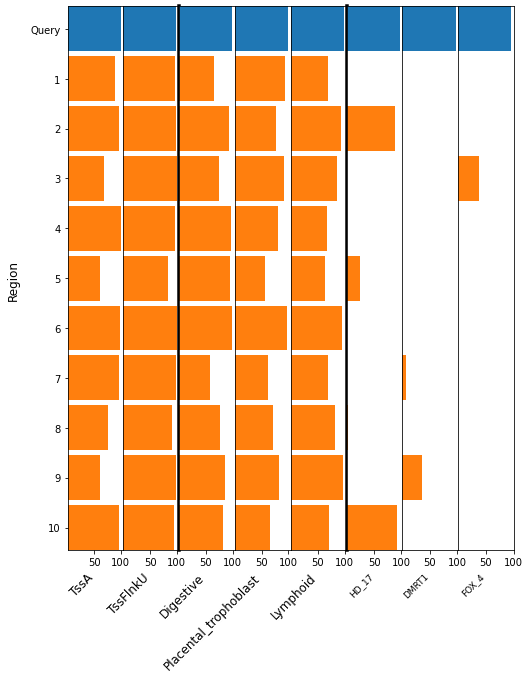

In [16]:
num_hits = 10
h = 0.9

fig, axes = plt.subplots(nrows=1, ncols=top_percents.shape[1], figsize=(top_percents.shape[1], num_hits))
fig.patch.set_facecolor('white')
fig.subplots_adjust(wspace=0)

axes = axes.ravel()

metric_sep_all = []
for m in np.unique(top_metrics):
    metric_sep_all.append(np.where(top_metrics==m)[0][-1])
metric_sep = np.sort(metric_sep_all)[:-1]

prior_spread = np.zeros(top_percents.shape[1])
for p, ind in zip(np.flip(priors[percent_arr_order]), 
                  np.flip(np.sort(metric_sep_all))):
    prior_spread[:ind+1] = p


# axes[0].spines['left'].set_linewidth(3)
for ax, factor in zip(axes, range(top_percents.shape[1])):
    ax.barh([num_hits], (100 - top_percents[0, factor]), height=h)
    ax.barh(np.flip(np.arange(num_hits)), (100 - top_percents[1:(num_hits + 1), factor]), height=h)
    
#     ax.set_xlim([80, 100])
#     ax.set_xticks([85, 90, 95])
#     ax.set_xticklabels([85, 90, 95], rotation=0)
    ax.set_xticks([50, 100])
    ax.set_xticklabels([50, 100], rotation=0)
    ax.set_xlabel(top_factors[factor], 
                  rotation=45, 
                  ha='right', 
                  fontsize=((4 * prior_spread[factor]) + 8))
    
    ax.set_yticks([])
    ax.set_ylim([-(h / 2), num_hits + (h / 2)])
    if factor in metric_sep:
        ax.spines['right'].set_linewidth(3.5)
    
    
axes[0].set_yticks(np.arange(num_hits+1))
axes[0].set_yticklabels(np.append(np.flip(np.arange(1, num_hits+1)), 'Query'))

# fig.supxlabel('Percentile', y=0)
fig.supylabel('Region')

Text(0.5, 0.95, 'Comparing Top Factor Percentiles between\nQuery and Most Similar Region Hits')

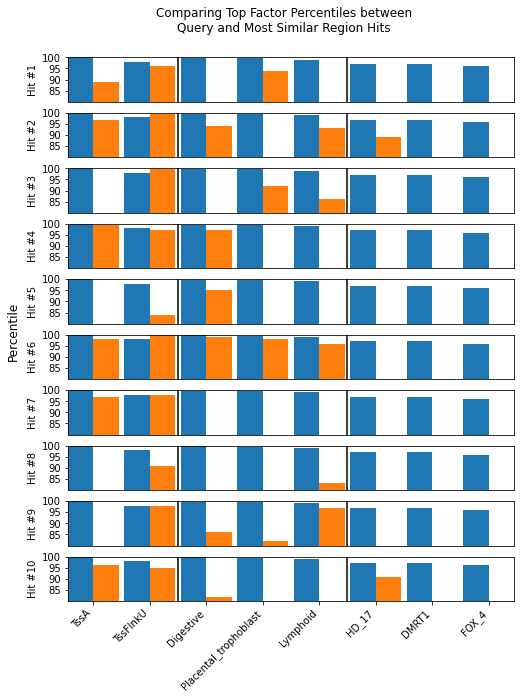

In [234]:
num_hits = 10

fig, axes = plt.subplots(nrows=num_hits, ncols=1, figsize=(top_percents.shape[1], num_hits))
fig.patch.set_facecolor('white')
fig.subplots_adjust(hspace=0.25)

axes = axes.ravel()

metric_sep = []
for m in np.unique(top_metrics):
    metric_sep.append(np.where(top_metrics==m)[0][-1])
metric_sep = np.sort(metric_sep)[:-1]

w = 0.45

for ax, hit in zip(axes, range(top_percents.shape[0] - 1)):
    
    ax.bar(np.arange(top_percents.shape[1]) - (w / 2), (100 - top_percents[0]), width=w)
    ax.bar(np.arange(top_percents.shape[1]) + (w / 2), (100 - top_percents[hit + 1]), width=w)
    ax.set_ylim([80, 100])
    ax.set_yticks([85, 90, 95, 100])
#     ax.set_yticklabels([15, 10, 5, 0])
    ax.set_ylabel('Hit #' + str(hit + 1))
    
    ax.set_xticks([])
    ax.set_xlim([-w, (top_percents.shape[1] - 1 + w)])
    
    
    for sep in metric_sep:
        ax.plot([sep + 0.5, sep + 0.5], [80, 100], c='k')
    
ax.set_xticks(np.arange(top_percents.shape[1]))
ax.set_xticklabels(top_factors, rotation=45, ha='right')
fig.supylabel('Percentile')
# patch = [mpatches.Patch(color='#1f77b4', label='Query'), 
#          mpatches.Patch(color='#ff7f0e', label='Hit')]
# axes[0].legend(handles=patch, loc=(0.825, 0.925))

fig.suptitle('Comparing Top Factor Percentiles between\nQuery and Most Similar Region Hits', y=0.95)

New data format. No TF. 20230221

In [5]:
class metriccolors:
    DHS = '\033[94m'
    TF = '\033[92m'
    EPI = '\033[91m'
    STANDARD = '\033[0m'
    BOLD = '\033[1m'
    UNDERLINE = '\033[4m'

def query_sentences(rank_arrs, factor_arrs_unordered, max_rank_arrs, 
                    metric_name_arrs_unordered, 
                    conversion_dicts_unordered, max_rank=20, 
                    multiple_rank_thresh=5,
                    max_factors_per_metric=3):
    num_metrics = len(rank_arrs)
    num_regions = len(rank_arrs[0])
#     num_metrics_skipped = 0

    # establish sentences
    sentences = np.array([''] * num_regions, dtype=object)
    sentence_start = f'This region ranks in the top '
    sentences[:] = sentence_start
    
    percent_arrs_unordered = []
    min_percents = []
    for rank_arr, max_rank_arr in zip(rank_arrs, max_rank_arrs):
        percent_arr, min_percent = percent_conversion(rank_arr, max_rank_arr)
        percent_arrs_unordered.append(percent_arr)
        min_percents.append(min_percent)
    min_percents = np.array(min_percents)

    # sorting by min percent
    percent_arr_order = np.argsort(min_percents)
    num_metrics_to_examine = len(min_percents[min_percents <= max_rank])
    percent_arrs = []
    factor_arrs = []
    metric_name_arrs = []
    conversion_dicts = []
    for p in percent_arr_order:
        percent_arrs.append(percent_arrs_unordered[p])
        factor_arrs.append(factor_arrs_unordered[p])
        metric_name_arrs.append(metric_name_arrs_unordered[p])
        conversion_dicts.append(conversion_dicts_unordered[p])
    
    top_percents = np.array([]).reshape(num_regions, -1)
    top_factors = np.array([])
    top_metrics = np.array([])
    # ranks for each metric
    for (
        percent_arr, factor_arr, metric_name,
        conversion_dict, metric_i
    ) in zip(
        percent_arrs[:num_metrics_to_examine], 
        factor_arrs[:num_metrics_to_examine], 
        metric_name_arrs[:num_metrics_to_examine], 
        conversion_dicts[:num_metrics_to_examine], 
        range(num_metrics_to_examine)
    ):
        # what is special about the query region?
        # sorting factors
        q_percent_sorted = np.sort(percent_arr[0])
        q_top_factors = np.argsort(percent_arr[0])

        # number of factors to examine for metric
        if len(q_percent_sorted[q_percent_sorted < multiple_rank_thresh]) > 0:
            num_factors = len(
                q_percent_sorted[
                    q_percent_sorted < multiple_rank_thresh
                ][:max_factors_per_metric]
            )
        elif len(q_percent_sorted[q_percent_sorted <= max_rank]) > 0:
            num_factors = 1
        else:
            print('BAD: this should not occur')
            num_factors = 0
#             num_metrics_skipped += 1
        # factor inds to examine
        factor_inds = q_top_factors[:num_factors]
        
        # factors and percentiles to save
        top_percents = np.hstack((top_percents, percent_arr[:, factor_inds]))
        top_factors = np.append(top_factors, factor_arr[factor_inds])
        top_metrics = np.append(top_metrics, np.array([metric_name] * len(factor_inds)))
        
        # coloring sentence sections
        if metric_name == 'DHS signal':
            metric_color = metriccolors.DHS
        elif metric_name == 'TF motif scores':
            metric_color = metriccolors.TF
        elif metric_name == 'chromatin states':
            metric_color = metriccolors.EPI
        sentences = np.char.add(sentences.astype(str), np.array([metric_color] * num_regions))
        
        # add factors to sentences
        for ind in factor_inds:
            factor_percent = percent_arr[:, ind]
            factor_percent = np.where((factor_percent % 1) != 0,
                                      factor_percent.astype(str),
                                      factor_percent.astype(int).astype(str))
            factor_percent = np.char.add(np.array([metriccolors.BOLD] * num_regions),
                                         factor_percent)
            factor_percent = np.char.add(factor_percent,
                                         np.array(['%' + metriccolors.STANDARD + 
                                                   metric_color + ' of '] * num_regions))
            factor_percent = np.char.add(factor_percent,
                                         np.array([conversion_dict[factor_arr[ind]]] * num_regions))

            # adding "," to factors
            if ((num_factors > 2) & (ind != factor_inds[-1])):
                factor_percent = np.char.add(factor_percent,
                                             np.array([', '] * num_regions))
            
            # adding "and" to factors
            if num_factors > 1:
                if ((num_factors == 2) & (ind == factor_inds[-2])):
                    factor_percent = np.char.add(factor_percent,
                                                 np.array([' '] * num_regions))
                if ind == factor_inds[-2]:
                    factor_percent = np.char.add(factor_percent,
                                                 np.array(['and '] * num_regions))
                    
            sentences = np.char.add(sentences.astype(str), factor_percent)
        
        if num_factors > 0:
            metric_label = np.array([' '])
            metric_label = np.char.add(metric_label, np.array([metric_name] * num_regions))

            # adding "," to metrics
            if ((num_metrics_to_examine > 2) & (metric_name != metric_name_arrs[:num_metrics_to_examine][-1])):
                metric_label = np.char.add(metric_label,
                                           np.array([metriccolors.STANDARD + ', '] * num_regions))

            # adding "and" to metrics
            if num_metrics_to_examine > 1:
                if ((num_metrics_to_examine == 2) & 
                    (metric_name == metric_name_arrs[:num_metrics_to_examine][-2])):
                    metric_label = np.char.add(metric_label,
                                               np.array([metriccolors.STANDARD + ' '] * num_regions))
                if metric_name == metric_name_arrs[:num_metrics_to_examine][-2]:
                    metric_label = np.char.add(metric_label,
                                               np.array([metriccolors.STANDARD + 'and '] * num_regions))

            sentences = np.char.add(sentences.astype(str), metric_label)
    sentences = np.char.add(sentences.astype(str), np.array([metriccolors.STANDARD + '.'] * num_regions))
    
    return sentences, top_percents, top_factors, top_metrics, percent_arr_order





def query_sentences_lim(rank_arrs, factor_arrs_unordered, max_rank_arrs, 
                        metric_name_arrs_unordered, 
                        conversion_dicts_unordered, max_rank=20, 
                        multiple_rank_thresh=5,
                        max_factors_per_metric=3):
    num_metrics = len(rank_arrs)
    num_regions = len(rank_arrs[0])
#     num_metrics_skipped = 0

    # establish sentences
    sentences = np.array([''] * num_regions, dtype=object)
    sentence_start = f'This region similarly ranks in the top '
    sentences[1:] = sentence_start
    sentences[0] = f'The query region ranks in the top '
    
    percent_arrs_unordered = []
    min_query_percents = []
    for rank_arr, max_rank_arr in zip(rank_arrs, max_rank_arrs):
        percent_arr, min_query_percent = percent_conversion(rank_arr, max_rank_arr)
        percent_arrs_unordered.append(percent_arr)
        min_query_percents.append(min_query_percent)
    min_query_percents = np.array(min_query_percents)

    # sorting by min percent
    percent_arr_order = np.argsort(min_query_percents)
    num_metrics_to_examine = len(min_query_percents[min_query_percents <= max_rank])
    percent_arrs = []
    factor_arrs = []
    metric_name_arrs = []
    conversion_dicts = []
    for p in percent_arr_order:
        percent_arrs.append(percent_arrs_unordered[p])
        factor_arrs.append(factor_arrs_unordered[p])
        metric_name_arrs.append(metric_name_arrs_unordered[p])
        conversion_dicts.append(conversion_dicts_unordered[p])
    
    # backups for regions that don't rank high enough for any factor
    backup_percent = np.ones(num_regions) * 101
    backup_factor = np.array([''] * num_regions, dtype=object)
    backup_metric = np.array([''] * num_regions, dtype=object)
    backup_color = np.array([''] * num_regions, dtype=object)
    
    top_percents = np.array([]).reshape(num_regions, -1)
    top_factors = np.array([])
    top_metrics = np.array([])
    # ranks for each metric
    metric_sections = []
    for (
        percent_arr, factor_arr, metric_name,
        conversion_dict, metric_i
    ) in zip(
        percent_arrs[:num_metrics_to_examine], 
        factor_arrs[:num_metrics_to_examine], 
        metric_name_arrs[:num_metrics_to_examine], 
        conversion_dicts[:num_metrics_to_examine], 
        range(num_metrics_to_examine)
    ):
        
        # what is special about the query region?
        # sorting factors
        q_percent_sorted = np.sort(percent_arr[0])
        q_top_factors = np.argsort(percent_arr[0])

        # number of factors to examine for metric
        if len(q_percent_sorted[q_percent_sorted < multiple_rank_thresh]) > 0:
            num_factors = len(
                q_percent_sorted[
                    q_percent_sorted < multiple_rank_thresh
                ][:max_factors_per_metric]
            )
        elif len(q_percent_sorted[q_percent_sorted <= max_rank]) > 0:
            num_factors = 1
        else:
            print('BAD: this should not occur')
            num_factors = 0
#             num_metrics_skipped += 1
        # factor inds to examine
        factor_inds = q_top_factors[:num_factors]
        
        # factors and percentiles to save
        top_percents = np.hstack((top_percents, percent_arr[:, factor_inds]))
        top_factors = np.append(top_factors, factor_arr[factor_inds])
        top_metrics = np.append(top_metrics, np.array([metric_name] * len(factor_inds)))
        
        # coloring sentence sections
        if metric_name == 'DHS signal':
            metric_color = metriccolors.DHS
        elif metric_name == 'TF motif scores':
            metric_color = metriccolors.TF
        elif metric_name == 'chromatin states':
            metric_color = metriccolors.EPI
#         sentences = np.char.add(sentences.astype(str), np.array([metric_color] * num_regions))
        
        # add factors to sentences
        num_region_factors = np.count_nonzero(percent_arr[:, factor_inds] <= max_rank, axis=1)
        factors_added = np.zeros(len(percent_arr), dtype=int)
        
        metric_section = np.array([''] * num_regions, dtype=object)
        
        print(factor_inds, metric_name)
        for ind in factor_inds:
            
            factor_percent = percent_arr[:, ind]
            
            # back ups
            backup_filter = factor_percent < backup_percent
            backup_percent = np.where(backup_filter, factor_percent, backup_percent)
            backup_factor = np.where(backup_filter, conversion_dict[factor_arr[ind]], backup_factor)
            backup_metric = np.where(backup_filter, metric_name, backup_metric)
            backup_color = np.where(backup_filter, metric_color, backup_color)
            
            # percent to string
            factor_percent = np.where((factor_percent % 1) != 0,
                                      factor_percent.astype(str),
                                      factor_percent.astype(int).astype(str))
            factor_percent = np.char.add(np.array([metriccolors.BOLD] * num_regions),
                                         factor_percent)
            factor_percent = np.char.add(factor_percent,
                                         np.array(['%' + metriccolors.STANDARD + 
                                                   metric_color + ' of '] * num_regions))
            factor_percent = np.char.add(factor_percent,
                                         np.array([conversion_dict[factor_arr[ind]]] * num_regions))
            

            # adding "," to factors
            factor_percent = np.where(
                ((num_region_factors > 2) & 
                 ((factors_added + 1) != num_region_factors)), 
                np.char.add(factor_percent, 
                            np.array([', '] * num_regions)),
                factor_percent
            )
            
            # adding "and" to factors
            factor_percent = np.where(
                ((num_region_factors == 2) & 
                 (factors_added == 0)), 
                np.char.add(factor_percent, 
                            np.array([' '] * num_regions)),
                factor_percent
            )
            
            factor_percent = np.where(
                ((num_region_factors > 1) & 
                 ((factors_added + 2) == num_region_factors)), 
                np.char.add(factor_percent, 
                            np.array(['and '] * num_regions)),
                factor_percent
            )
            
            # limit to when a region is also ranks high for factor
            factor_percent = np.where(percent_arr[:, ind] <= max_rank, factor_percent, '')
            factors_added[np.where(percent_arr[:, ind] <= max_rank)[0]] += 1
            metric_section = np.char.add(metric_section.astype(str), factor_percent)
            
        metric_sections.append(metric_section)
#             sentences = np.char.add(sentences.astype(str), factor_percent)

#         if num_factors > 0:
#             metric_label = np.array([' '])
#             metric_label = np.char.add(metric_label, np.array([metric_name] * num_regions))

#             # adding "," to metrics
#             if ((num_metrics_to_examine > 2) & (metric_name != metric_name_arrs[:num_metrics_to_examine][-1])):
#                 metric_label = np.char.add(metric_label,
#                                            np.array([metriccolors.STANDARD + ', '] * num_regions))

#             # adding "and" to metrics
#             if num_metrics_to_examine > 1:
#                 if ((num_metrics_to_examine == 2) & 
#                     (metric_name == metric_name_arrs[:num_metrics_to_examine][-2])):
#                     metric_label = np.char.add(metric_label,
#                                                np.array([metriccolors.STANDARD + ' '] * num_regions))
#                 if metric_name == metric_name_arrs[:num_metrics_to_examine][-2]:
#                     metric_label = np.char.add(metric_label,
#                                                np.array([metriccolors.STANDARD + 'and '] * num_regions))

#             sentences = np.char.add(sentences.astype(str), metric_label)


    metric_sections = np.array(metric_sections)
    num_region_metrics = np.count_nonzero(metric_sections!='', axis=0)
    metrics_added = np.zeros(len(percent_arr), dtype=int)
    for (
         i, 
         metric_name, 
         init_metric_section
    ) in zip(
        range(num_metrics_to_examine), 
        metric_name_arrs[:num_metrics_to_examine],
        metric_sections
    ):
        
        # coloring sentence sections
        if metric_name == 'DHS signal':
            metric_color = metriccolors.DHS
        elif metric_name == 'TF motif scores':
            metric_color = metriccolors.TF
        elif metric_name == 'chromatin states':
            metric_color = metriccolors.EPI
        
        metric_section = init_metric_section
        
        metric_section = np.char.add(np.array([metric_color] * num_regions), metric_section)
        
        metric_section = np.where(
            metric_section != '',
            np.char.add(metric_section, 
                        np.array([' ' + metric_name] * num_regions)),
            metric_section
        )
        
        metric_section = np.char.add(metric_section, 
                                     np.array([metriccolors.STANDARD] * num_regions))
        
        # adding "," to metrics
        metric_section = np.where(
            ((num_region_metrics > 2) & 
             ((metrics_added + 1) != num_region_metrics)), 
            np.char.add(metric_section, 
                        np.array([', '] * num_regions)),
            metric_section
        )
        
        # adding "and" to metric sections
        metric_section = np.where(
            ((num_region_metrics == 2) & 
             (metrics_added == 0)), 
            np.char.add(metric_section, 
                        np.array([' '] * num_regions)),
            metric_section
        )

        metric_section = np.where(
            ((num_region_metrics > 1) & 
             ((metrics_added + 2) == num_region_metrics)), 
            np.char.add(metric_section, 
                        np.array(['and '] * num_regions)),
            metric_section
        )
        # limit to when a region is also ranks high for factor
        metric_section = np.where(init_metric_section  != '', metric_section, '')
        metrics_added[np.where(init_metric_section != '')[0]] += 1
        sentences = np.char.add(sentences.astype(str), metric_section)
        
#     print(backup_percent, backup_factor, backup_metric, backup_color) #### need to finish back ups
    backup_percent = np.where((backup_percent % 1) != 0,
                              backup_percent.astype(str),
                              backup_percent.astype(int).astype(str))
    empty_mask = sentences == 'This region similarly ranks in the top '
    # bold and in metric color
    sentences = np.where(empty_mask,
                         np.char.add(sentences, 
                                     np.char.add(backup_color.astype(str),
                                                 np.array([metriccolors.BOLD]))),
                         sentences)
    # percent value
    sentences = np.where(empty_mask,
                         np.char.add(sentences, backup_percent),
                         sentences)
    # unbold
    sentences = np.where(empty_mask,
                         np.char.add(sentences,
                                     np.char.add(np.array(['%' + metriccolors.STANDARD] * num_regions),
                                                 backup_color)),
                         sentences)
    # factor
    sentences = np.where(empty_mask,
                         np.char.add(sentences,
                                     np.char.add(np.array([' of '] * num_regions).astype(str),
                                                 backup_factor.astype(str))),
                         sentences)
    # metric
    sentences = np.where(empty_mask,
                         np.char.add(sentences,
                                     np.char.add(np.array([' '] * num_regions), 
                                                backup_metric.astype(str))),
                         sentences)    
    
    sentences = np.char.add(sentences.astype(str), np.array([metriccolors.STANDARD + '.'] * num_regions))
    
    return sentences, top_percents, top_factors, top_metrics, percent_arr_order


# def percent_conversion(rank_arr, max_rank_arr):
#     max_pseudo = max_rank_arr + 1  # pseudocount
#     percent = (1 - (rank_arr / max_pseudo)) * 100
#     percent = np.where(percent < 1,
#                        np.ceil(percent * 100) / 100,
#                        np.ceil(percent))
#     min_query_percent = np.min(percent[0])
    
#     return percent, min_query_percent

# sentences = query_sentences(rank_arrs, factor_arrs, max_rank_arrs, metric_name_arrs, conversion_dicts)














def load_per(per_f):
    hdf5_f = h5py.File(per_f, 'r')
    percentile = hdf5_f['percentile'][:]
    factors = np.char.decode(hdf5_f['factors'][:])
    color = np.char.decode(hdf5_f['colors'][:])
    hdf5_f.close()
    return percentile, factors, color

def simsearch(DHS_per_f, epi_per_f, roi, target_factors):
    # load region percentiles
    DHS_per, DHS_factors, DHS_color = load_per(DHS_per_f)
    epi_per, epi_factors, epi_color = load_per(epi_per_f)

    # join data from each metric
    percents = np.hstack((DHS_per, epi_per))

    factor_order = np.append(DHS_factors, epi_factors)
    metric_order = np.append(np.array(['DHSs'] * len(DHS_factors)),
                             np.array(['chromatin states'] *
                                      len(epi_factors)))
    colors = np.append(DHS_color, epi_color)

    # convolution
    roi_percents = percents[roi, target_factors]
    roi_conv_all = percents[:, target_factors] * roi_percents

    # fusion
    roi_sim_all = 1 - np.prod(1 - roi_conv_all, axis=1)

    # most similar regions
    top_regions = np.argsort(-roi_sim_all)[:101]
    top_regions = np.append(roi, top_regions[top_regions != roi][:100])

    return (top_regions, roi_sim_all[top_regions], roi_conv_all[top_regions],
            percents[top_regions], factor_order, metric_order, colors)


def top100_sentences(top_regions, roi_per, factor_order, target_factors, metric_order):
    
    # conversion dictionary
    conversion_dict = {
        'EnhA1': 'active enhancer 1',
        'EnhA2': 'active enhancer 2',
        'EnhBiv': 'bivalent enhancer',
        'EnhG1': 'genic enhancer 1',
        'EnhG2': 'genic enhancer 2',
        'EnhWk': 'weak enhancer',
        'Het': 'heterochromatin',
        'Quies': 'quiescent',
        'ReprPC': 'repressed polycomb',
        'ReprPCWk': 'weak repressed polycomb',
        'TssA': 'active TSS',
        'TssBiv': 'bivalent TSS',
        'TssFlnk': 'flanking TSS',
        'TssFlnkD': 'downstream flanking TSS',
        'TssFlnkU': 'upstream flanking TSS',
        'Tx': 'strong transcription',
        'TxWk': 'weak transcription',
        'ZNF_Rpts': 'ZNF genes + repeats',
        'Cancer_epithelial': 'cancer/epithelial',
        'Cardiac': 'cardiac',
        'Digestive': 'digestive',
        'Lymphoid': 'lymphoid',
        'Musculoskeletal': 'musculoskeletal',
        'Myeloid_erythroid': 'myeloid/erythroid',
        'Neural': 'neural',
        'Organdevel_renal': 'organ development/renal',
        'Placental_trophoblast': 'placental/trophoblast',
        'Primitive_embryonic': 'primitive/embryonic',
        'Pulmonarydevel': 'pulmonary development',
        'Renal_cancer': 'renal/cancer',
        'StromalA': 'stromal A',
        'StromalB': 'stromal B',
        'Tissueinvariant': 'tissue invariant',
        'Vascular_endothelial': 'vascular/endothelial'
    }
    
    sentences = query_sentences_lim(rank_arrs, factor_arrs,
                                    max_rank_arrs, metric_name_arrs, 
                                    conversion_dicts, max_factors_per_metric=3)
    

def narrate_sim(top_regions, roi_per, factor_order, metric_order, target_factors, conversion_dict, metriccolors, thresh=0.9):
    query = top_regions[0]
    hits = top_regions[1:]
#     factor_scores = roi_conv[1:]  # selected factor convolution
#     factor_scores = np.vstack((roi_per[0], roi_per[0] * roi_per[1:]))
    factor_scores = roi_per[0] * roi_per  # > sqrt of thresh for query region
    
    sentences = []
    for region, factor_score in zip(top_regions, factor_scores):
        key_factors = np.where(factor_score > thresh)[0]
        if len(key_factors) > 0:
            if region == query:
                sentence = '<div>The query region ranks highly for '
            else:
                sentence = '<div>This region is highly similar to the query region in terms of '
            key_factor_names = factor_order[key_factors]
            key_metric_names = metric_order[key_factors]
            m_sections = []
            for m in np.unique(key_metric_names):
                m_inds = np.where(key_metric_names == m)[0]
                m_factors = key_factor_names[m_inds]
                
                target_factor_inds = np.where(
                    np.isin(m_factors,
                            factor_order[target_factors])
                )[0]
                
                m_factors = list(map(conversion_dict.get, m_factors))
                for t in target_factor_inds:
                    m_factors[t] = (metriccolors['BOLD'] + m_factors[t] +
                                    metriccolors['UNBOLD'])
                factors_joined = metriccolors[m]
                if len(m_factors) > 2:
                    factors_joined += ', '.join(m_factors[:-1])
                    factors_joined += ', and ' + m_factors[-1]
                elif len(m_factors) == 2:
                    factors_joined += ' and '.join(m_factors)
                else:
                    factors_joined += m_factors[0]
                    
                factors_joined += ' ' + m + metriccolors['STANDARD']
                m_sections.append(factors_joined)
            if len(m_sections) > 2:
                metrics_joined = ', '.join(m_sections[:-1])
                metrics_joined += ', and ' + m_sections[-1]
            if len(m_sections) == 2:
                metrics_joined = ' and '.join(m_sections)
            else:
                metrics_joined = m_sections[0]
                
            sentence += metrics_joined + '.</div>'
        
        else:
            sentence = '<div></div>'
        sentences.append(sentence)
    return sentences

# conversion dictionary
conversion_dict = {
    'EnhA1': 'active enhancer 1',
    'EnhA2': 'active enhancer 2',
    'EnhBiv': 'bivalent enhancer',
    'EnhG1': 'genic enhancer 1',
    'EnhG2': 'genic enhancer 2',
    'EnhWk': 'weak enhancer',
    'Het': 'heterochromatin',
    'Quies': 'quiescent',
    'ReprPC': 'repressed polycomb',
    'ReprPCWk': 'weak repressed polycomb',
    'TssA': 'active TSS',
    'TssBiv': 'bivalent TSS',
    'TssFlnk': 'flanking TSS',
    'TssFlnkD': 'downstream flanking TSS',
    'TssFlnkU': 'upstream flanking TSS',
    'Tx': 'strong transcription',
    'TxWk': 'weak transcription',
    'ZNF_Rpts': 'ZNF genes + repeats',
    'Cancer_epithelial': 'cancer/epithelial',
    'Cardiac': 'cardiac',
    'Digestive': 'digestive',
    'Lymphoid': 'lymphoid',
    'Musculoskeletal': 'musculoskeletal',
    'Myeloid_erythroid': 'myeloid/erythroid',
    'Neural': 'neural',
    'Organdevel_renal': 'organ development/renal',
    'Placental_trophoblast': 'placental/trophoblast',
    'Primitive_embryonic': 'primitive/embryonic',
    'Pulmonarydevel': 'pulmonary development',
    'Renal_cancer': 'renal/cancer',
    'StromalA': 'stromal A',
    'StromalB': 'stromal B',
    'Tissueinvariant': 'tissue invariant',
    'Vascular_endothelial': 'vascular/endothelial'
}

metriccolors = {
    'DHSs': '<span style={{color: "blue"}}>',
    'chromatin states': '<span style={{color: "red"}}>',
    'STANDARD': '</span>',
    'BOLD': '<b>',
    'UNBOLD': '</b>'
}

In [6]:
datadir = '/home/ctrader/region_similarity/data/rank_based/'
DHS_hdf5_path = datadir + 'regions_25kb_CT20230214.DHS.factornormNMF.sum_enrich_corank_percentile.hdf5'
epi_hdf5_path = datadir + 'regions_25kb_CT20230214.epilogos.statesum_rank_percentile.hdf5'

target_factors = np.array([3, 31])

roi = 59157

(top_regions, roi_sim, 
 roi_conv, roi_per, 
 factor_order, metric_order, 
 colors) = simsearch(DHS_hdf5_path, epi_hdf5_path, roi, target_factors)

# (sentences, top_percents,
#  top_factors, top_metrics,
#  percent_arr_order) = top100_sentences(DHS_hdf5_path, DHS_mapped_path, TF_hdf5_path,
#                                        TF_mapped_path, epi_hdf5_path,
#                                        top_100)

sentences = narrate_sim(top_regions, roi_per, 
                        factor_order, metric_order, 
                        target_factors, conversion_dict,
                        metriccolors)

In [7]:
for s in sentences:
    print(s)

<div>The query region ranks highly for <span style={{color: "blue"}}><b>cardiac</b> and organ development/renal DHSs</span> and <span style={{color: "red"}}>bivalent TSS, bivalent enhancer, and <b>repressed polycomb</b> chromatin states</span>.</div>
<div>This region is highly similar to the query region in terms of <span style={{color: "blue"}}><b>cardiac</b>, primitive/embryonic, and organ development/renal DHSs</span> and <span style={{color: "red"}}>bivalent TSS, bivalent enhancer, and <b>repressed polycomb</b> chromatin states</span>.</div>
<div>This region is highly similar to the query region in terms of <span style={{color: "blue"}}><b>cardiac</b> and primitive/embryonic DHSs</span> and <span style={{color: "red"}}>bivalent TSS, bivalent enhancer, and <b>repressed polycomb</b> chromatin states</span>.</div>
<div>This region is highly similar to the query region in terms of <span style={{color: "blue"}}><b>cardiac</b> DHSs</span> and <span style={{color: "red"}}>bivalent TSS, bi

Using detail level as a threshold for how many factors to include

In [162]:
def simsearch(DHS_per_f, epi_per_f, roi, included_factors,
              detail_level):
    # load region percentiles
    DHS_per, DHS_factors, DHS_color = load_per(DHS_per_f)
    epi_per, epi_factors, epi_color = load_per(epi_per_f)

    # join data from each metric
    percents = np.hstack((DHS_per, epi_per))
    factor_order = np.append(DHS_factors, epi_factors)
    metric_order = np.append(np.array(['DHSs'] * len(DHS_factors)),
                             np.array(['chromatin states'] *
                                      len(epi_factors)))
    colors = np.append(DHS_color, epi_color)

    # factors the query region rank highest in
    query_factor_order = np.argsort(-percents[roi])

    # factors to search over based on detail level
    target_factors = query_factor_order[
        np.isin(query_factor_order, included_factors)
    ][:detail_level]
    
    # convolution
    roi_percents = percents[roi, target_factors]
    roi_conv_all = percents[:, target_factors] * roi_percents

    # fusion
    roi_sim_all = 1 - np.prod(1 - roi_conv_all, axis=1)

    # most similar regions
    top_regions = np.argsort(-roi_sim_all)[:101]
    top_regions = np.append(roi, top_regions[top_regions != roi][:100])

    return (top_regions, roi_sim_all[top_regions], roi_conv_all[top_regions],
            percents[top_regions], factor_order, metric_order, colors,
            query_factor_order, target_factors)


def narrate_detail_level(top_regions, roi_per, factor_order, metric_order, included_factors, detail_level, conversion_dict, metriccolors, thresh=0.9):
    query = top_regions[0]
    hits = top_regions[1:]
    factor_scores = roi_per[0] * roi_per  # > sqrt of thresh for query region

    sentences = []
    for region, factor_score in zip(top_regions, factor_scores):
        factor_score_sort = np.argsort(-factor_score)
        key_factors = factor_score_sort[
            ((factor_score[factor_score_sort] > thresh) & 
             (np.isin(factor_score_sort, included_factors)))
        ][:detail_level]

        if len(key_factors) > 0:
            if region == query:
                sentence = '<div>The query region ranks highly for '
            else:
                sentence = '<div>This region is highly similar to the query region in terms of '
            key_factor_names = factor_order[key_factors]
            key_metric_names = metric_order[key_factors]

            string_factors = []
            for factor, metric in zip(key_factor_names, key_metric_names):
                if metric == 'chromatin states':
                    string_factor = metriccolors['chromatin states']
                elif metric == 'DHSs':
                    string_factor = metriccolors['DHSs']
                string_factor += factor + ' ' + metric + metriccolors['STANDARD']
                string_factors.append(string_factor)

            if len(string_factors) > 2:
                sentence += ', '.join(string_factors[:-1])
                sentence += ', and ' + string_factors[-1]
            elif len(string_factors) == 2:
                sentence += ' and '.join(string_factors[:-1])
            else:
                sentence += string_factors[0]
            sentence += '.</div>'
        else:
            sentence = '<div></div>'
        sentences.append(sentence)
    return sentences

In [163]:
datadir = '/home/ctrader/region_similarity/data/rank_based/'
DHS_per_f = datadir + 'regions_25kb_CT20230214.DHS.factornormNMF.sum_enrich_corank_percentile.hdf5'
epi_per_f = datadir + 'regions_25kb_CT20230214.epilogos.statesum_rank_percentile.hdf5'

# auto_factor_selection = 'true'
detail_level = 3
included_factors = np.arange(34)[np.arange(34)!=30]
included_factors_str = '[' + ','.join(included_factors.astype(str)) + ']'
    included_factors = np.int_(
        included_factors_str.strip('[').strip(']').split(',')
    )




(top_regions, roi_sim, roi_conv,
 roi_per, factor_order, metric_order,
 colors, query_factor_order, 
 target_factors) = simsearch(DHS_per_f, epi_per_f, 
                             roi, included_factors, 
                             detail_level)

    sentences = narrate_detail_level(top_regions, roi_per,
                                     factor_order, metric_order,
                                     included_factors, detail_level, conversion_dict,
                                     metriccolors)

In [164]:
for s in sentences:
    print(s)

<div>The query region ranks highly for <span style={{color: "red"}}>TssBiv chromatin states</span>, <span style={{color: "blue"}}>Cardiac DHSs</span>, and <span style={{color: "red"}}>ReprPC chromatin states</span>.</div>
<div>This region is highly similar to the query region in terms of <span style={{color: "red"}}>TssBiv chromatin states</span>, <span style={{color: "blue"}}>Cardiac DHSs</span>, and <span style={{color: "red"}}>ReprPC chromatin states</span>.</div>
<div>This region is highly similar to the query region in terms of <span style={{color: "red"}}>TssBiv chromatin states</span>, <span style={{color: "blue"}}>Cardiac DHSs</span>, and <span style={{color: "red"}}>ReprPC chromatin states</span>.</div>
<div>This region is highly similar to the query region in terms of <span style={{color: "red"}}>TssBiv chromatin states</span>, <span style={{color: "blue"}}>Cardiac DHSs</span>, and <span style={{color: "red"}}>ReprPC chromatin states</span>.</div>
<div>This region is highly s